In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from sklearn.model_selection import train_test_split

In [ ]:
# Load dataset
PATH = "./Dataset/"
CLASS_NAMES = sorted(os.listdir(PATH))
print("Classes:", CLASS_NAMES)

Classes: ['Broccoli', 'Carrot', 'Cucumber', 'Tomato']


In [7]:
rows, cols = 224, 224
x, y = [], []

for label, class_name in enumerate(CLASS_NAMES):
    for img_name in os.listdir(PATH + class_name):
        img = keras.utils.load_img(f"{PATH}{class_name}/{img_name}", 
                                   target_size=(rows, cols), color_mode="grayscale")

        x.append(keras.utils.img_to_array(img))
        y.append(label)

x, y = np.array(x), np.array(y)

# Random shuffle: satu urutan acak dipakai untuk x dan y agar tetap berpasangan
idx = np.random.permutation(len(x))
x, y = x[idx], y[idx]

print(x.shape, y.shape)
print(np.unique(y, return_counts=True))

(2000, 224, 224, 1) (2000,)
(array([0, 1, 2, 3]), array([500, 500, 500, 500]))


In [8]:
# split dataset
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y) 
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(len(x_train), len(x_val), len(x_test))

1600 200 200


In [9]:
# data preprocessing
# 1. reshape 
x_train = x_train.reshape(-1, rows, cols, 1).astype("float32") / 255.0
x_val = x_val.reshape(-1, rows, cols, 1).astype("float32") / 255.0
x_test = x_test.reshape(-1, rows, cols, 1).astype("float32") / 255.0

#  one hot encoding
NUM_CLASSES = len(CLASS_NAMES)
y_train = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test = keras.utils.to_categorical(y_test, NUM_CLASSES)

In [ ]:
# arsitektur dcnn
model = keras.Sequential([
    # input layer
    keras.layers.Input(shape=(rows, cols, 1)),

    # hidden layer: conv -> pool -> conv -> pool -> flatten
    keras.layers.Conv2D(8, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.Conv2D(16, (5, 5), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2),
    keras.layers.Flatten(),

    # output layer : dense relu -> dense softmax
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])

# ini diubah jadi 8, 16, 16, 64 loss nya jadi turun ke 0.7

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 220, 220, 8)    │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 110, 110, 8)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 106, 106, 16)   │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 102, 102, 16)   │         6,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 51, 51, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 41616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     2,663,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,673,588 (10.20 MB)

 Trainable params: 2,673,588 (10.20 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# training
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history = model.fit(x_train, y_train, batch_size=32, epochs=10,
                    validation_data=(x_val, y_val))

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 163ms/step - accuracy: 0.4837 - loss: 1.1274 - val_accuracy: 0.7150 - val_loss: 0.6720
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 152ms/step - accuracy: 0.7837 - loss: 0.5596 - val_accuracy: 0.7850 - val_loss: 0.5424
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 148ms/step - accuracy: 0.8863 - loss: 0.3065 - val_accuracy: 0.9000 - val_loss: 0.2981
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step - accuracy: 0.9225 - loss: 0.2010 - val_accuracy: 0.8850 - val_loss: 0.3203
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 146ms/step - accuracy: 0.9538 - loss: 0.1316 - val_accuracy: 0.8950 - val_loss: 0.3244
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 135ms/step - accuracy: 0.9563 - loss: 0.1081 - val_accuracy: 0.8850 - val_loss: 0.5214
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 143ms/step - accuracy: 0.9787 - loss: 0.0674 - val_accuracy: 0.8750 - val_loss: 0.4295
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 7s 147ms/step - accuracy: 0.9500 - loss: 0.1534 - val_accuracy: 0

In [18]:
# predict & evaluate

# predict: probabilitas per kelas -> ambil kelas terbesar
pred = model.predict(x_test)
pred_class = np.argmax(pred, axis=1)
true_class = np.argmax(y_test, axis=1)

pred_loss = keras.losses.categorical_crossentropy(y_test, pred).numpy().mean()
pred_acc = (pred_class == true_class).mean()
print(f"[Predict] Loss: {pred_loss:.4f} | Accuracy: {pred_acc:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step
[Predict] Loss: 0.7817 | Accuracy: 0.8550


In [17]:
# evaluate

loss, acc = model.evaluate(x_test, y_test)
print(f"[Evaluate] Loss: {loss:.4f} | Accuracy: {acc:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.8550 - loss: 0.7973
[Evaluate] Loss: 0.7973 | Accuracy: 0.8550


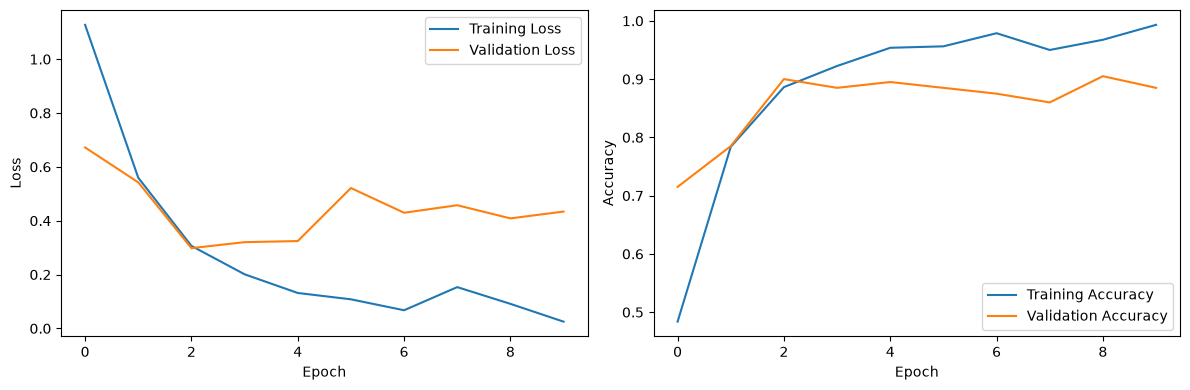

In [19]:
# plot evaluation metrics

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()